# DataTrust — Plan del proyecto

**No es un entregable oficial.** Es la versión con código de `plan_proyecto.md`



In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.facecolor"] = "white"

listings = pd.read_csv("data/airbnb_bcn/listings.csv", low_memory=False)
con = sqlite3.connect("database/airbnb.db")
print(f"Alojamientos: {len(listings):,}".replace(",", "."))


Alojamientos: 15.293


## ¿De qué trata el proyecto?

Auditoría de calidad de datos sobre Airbnb Barcelona: reviso si los datos
públicos están bien o tienen errores, antes de usarlos para sacar
conclusiones de negocio.

## ¿Qué voy a demostrar?

Que si no revisas los datos antes de usarlos, las conclusiones que saques
pueden estar mal — con un caso real y números concretos.

## ¿Cuál es el problema? — los 14 hallazgos, con código

### En los alojamientos (`listings`)


In [2]:
# 1. Columnas 100% vacias
nulos_pct = listings.isna().mean() * 100
cols_vacias = nulos_pct[nulos_pct == 100.0]
print(f"Columnas 100% vacias: {len(cols_vacias)}")
print(list(cols_vacias.index))


Columnas 100% vacias: 12
['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'calendar_updated', 'instant_bookable']


In [3]:
# 2. Licencia: sin dato verificable, y el caso del NRUA
import re

def clasifica_licencia(valor):
    if pd.isna(valor):
        return "Sin dato"
    valor = str(valor)
    if "Exempt" in valor:
        return "Exento (declarado)"
    if re.search(r"HUTB[-]?\d{4,}", valor, flags=re.IGNORECASE):
        return "Con numero HUTB (registro catalan)"
    if re.search(r"National registration number", valor, flags=re.IGNORECASE):
        return "Con numero NRUA (registro estatal, desde jul. 2025)"
    return "Otro / no clasificable"

listings["license_categoria"] = listings["license"].apply(clasifica_licencia)
print(listings["license_categoria"].value_counts())

sin_dato_ok = listings["license_categoria"].isin(["Sin dato", "Otro / no clasificable"])
pct_sin_dato = sin_dato_ok.mean() * 100
n_nrua = (listings["license_categoria"] == "Con numero NRUA (registro estatal, desde jul. 2025)").sum()
pct_nrua = n_nrua / len(listings) * 100
print(f"\nSin dato verificable: {pct_sin_dato:.1f}%")
print(f"Con NRUA (riesgo de no reconocerlo): {n_nrua} ({pct_nrua:.1f}%)")


license_categoria
Con numero HUTB (registro catalan)                     7194
Exento (declarado)                                     3924
Sin dato                                               3043
Con numero NRUA (registro estatal, desde jul. 2025)     948
Otro / no clasificable                                  184
Name: count, dtype: int64

Sin dato verificable: 21.1%
Con NRUA (riesgo de no reconocerlo): 948 (6.2%)


**El problema de las licencias**: el campo `license` deberia indicar si un
alojamiento tiene registro turistico valido. El 21,1% no tiene un dato
verificable (sin informacion, o un texto que no encaja con ningun formato
conocido). Ademas, Espana creo en julio de 2025 un registro nuevo (NRUA),
distinto del catalan (HUTB) que ya existia. Un analisis que no reconozca el
formato de texto del NRUA clasificaria como "sin licencia" a anuncios que en
realidad si la tienen -- en estos datos, 948 anuncios (6,2%). Por eso la
funcion de abajo distingue 5 categorias, no solo "tiene licencia / no tiene".


In [4]:
# 3. Precio y datos estructurales
sin_precio = listings["price"].isna()
pct_precio_nulo = sin_precio.mean() * 100
pct_estructura_nula = listings[["bedrooms", "bathrooms", "beds"]].isna().mean() * 100
print(f"Precio nulo: {pct_precio_nulo:.1f}%")
print(pct_estructura_nula.round(1))

# Consecuencia del precio nulo sobre el target del proyecto
tiene_revenue_check = listings["estimated_revenue_l365d"].notna()
print()
print("Anuncios sin precio:", sin_precio.sum())
print("  de esos, con estimated_revenue_l365d calculado:", (sin_precio & tiene_revenue_check).sum())
print("  de esos, sin estimated_revenue_l365d:", (sin_precio & ~tiene_revenue_check).sum())

# Donde se concentran los datos estructurales nulos
estructura_nula = listings[["bedrooms", "bathrooms", "beds"]].isna().any(axis=1)
print()
print("% con algun dato estructural nulo, por tipo de alojamiento:")
print(listings.groupby("room_type").apply(lambda d: estructura_nula.loc[d.index].mean()*100, include_groups=False).round(1))


Precio nulo: 12.7%
bedrooms     16.8
bathrooms    23.3
beds         16.0
dtype: float64

Anuncios sin precio: 1938
  de esos, con estimated_revenue_l365d calculado: 0
  de esos, sin estimated_revenue_l365d: 1938

% con algun dato estructural nulo, por tipo de alojamiento:
room_type
Entire home/apt    19.9
Hotel room         23.5
Private room       65.0
Shared room        54.6
dtype: float64


**Sobre el precio**: los 1.938 anuncios sin precio coinciden al 100% con
anuncios que tampoco tienen `estimated_revenue_l365d`. Como el ingreso se
calcula como ocupacion x precio, si falta el precio, Inside Airbnb no pudo
calcular el ingreso en absoluto para esos anuncios -- no es solo un dato
que falta, es un bloqueo directo: esos 1.938 anuncios quedan fuera de todo
el caso de negocio y del modelo, no solo marcados.

**Sobre los datos estructurales** (bedrooms/bathrooms/beds): no estan
repartidos al azar -- se concentran mucho mas en habitaciones privadas
(65%) y compartidas (54,6%) que en pisos completos (19,9%) u hoteles
(23,5%). Tiene sentido: quien alquila solo una habitacion de su propia casa
es menos probable que rellene "numero de baños" o "numero de camas" con
precision, porque son espacios compartidos o el dato es ambiguo.


### En las reseñas (`reviews`) y el calendario (`calendar`)

Estas tablas son grandes (más de 1 millón de reseñas, 5,6 millones de filas
de calendario), así que uso SQL contra la base de datos en vez de cargar los
CSV completos en memoria — es el mismo criterio que ya se usa en el
notebook 05 para verificar antes/después del tratamiento.


In [5]:
# Reviews: huerfanas y duplicadas
huerfanas_reviews = pd.read_sql("""
    SELECT COUNT(*) as n FROM reviews r
    WHERE r.listing_id NOT IN (SELECT id FROM listings)
""", con)
print("Reseñas huerfanas:", huerfanas_reviews["n"][0])

# Duplicados exactos de texto (comments), en cualquier listing, no solo dentro
# del mismo alojamiento -- coincide con la cifra ya usada en el resto del proyecto.
reviews = pd.read_csv("data/airbnb_bcn/reviews.csv", low_memory=False)
dup_comentarios = reviews.dropna(subset=["comments"]).duplicated(subset=["comments"]).sum()
print(f"Comentarios duplicados exactos: {dup_comentarios:,}".replace(",", "."))

# Diagnostico: son copias largas (spam) o frases cortas genericas?
dup_mask = reviews.dropna(subset=["comments"]).duplicated(subset=["comments"], keep=False)
reviews_sin_nulo = reviews.dropna(subset=["comments"])
print()
print("Longitud media del texto duplicado:", round(reviews_sin_nulo[dup_mask]["comments"].str.len().mean()))
print("Longitud media del texto NO duplicado:", round(reviews_sin_nulo[~dup_mask]["comments"].str.len().mean()))
print(reviews_sin_nulo[dup_mask]["comments"].value_counts().head(5))


Reseñas huerfanas: 6592


Comentarios duplicados exactos: 48.302



Longitud media del texto duplicado: 15


Longitud media del texto NO duplicado: 256
comments
.                 2719
Good               707
Great location     664
Great place        542
Great              491
Name: count, dtype: int64


**Sobre las reseñas huerfanas**: hacen referencia a un `listing_id` que ya
no existe en el snapshot actual de `listings` -- probablemente alojamientos
retirados de la plataforma entre que se escribieron esas reseñas y la fecha
de este snapshot. No hay alojamiento al que atribuirlas, asi que se excluyen.

**Sobre los duplicados**: no son reseñas largas copiadas -- el texto
duplicado promedio tiene 15 caracteres, frente a 256 de las reseñas no
duplicadas. Son frases genericas cortas que huespedes distintos escriben de
forma independiente ("Good", "Great location", "Top"), mas un caso
especial: un simple punto "." aparece 2.719 veces, probablemente cuando
alguien deja una valoracion sin escribir texto. No es indicio de reseñas
falsas -- es el resultado natural de que frases cortas y genericas se
repitan por casualidad entre miles de huespedes distintos.


In [6]:
# Calendar: filas huerfanas y el valor de relleno por defecto (maximum_nights = 1125)
huerfanas_cal = pd.read_sql("""
    SELECT COUNT(*) as n FROM calendar c
    WHERE c.listing_id NOT IN (SELECT id FROM listings)
""", con)
print("Filas de calendario huerfanas:", huerfanas_cal["n"][0])

total_cal = pd.read_sql("SELECT COUNT(*) as n FROM calendar", con)["n"][0]
relleno = pd.read_sql("SELECT COUNT(*) as n FROM calendar WHERE maximum_nights = 1125", con)["n"][0]
print(f"Filas con maximum_nights = 1125 (relleno por defecto): {relleno:,} ({relleno/total_cal*100:.1f}%)".replace(",", "."))


Filas de calendario huerfanas: 41245


Filas con maximum_nights = 1125 (relleno por defecto): 1.478.636 (26.3%)


**Sobre las filas huerfanas**: mismo caso que en reviews -- hacen referencia
a un `listing_id` que ya no existe en el snapshot actual, asi que se
excluyen.

**Sobre el valor de relleno (`maximum_nights = 1125`)**: 1.125 noches son
poco mas de 3 años -- nadie fija una estancia maxima real de 3 años. Es el
valor por defecto que usa la plataforma cuando el anfitrion nunca definio
explicitamente un maximo. Usar este campo sin tenerlo en cuenta haria
parecer que una cuarta parte de los anuncios tiene una politica de estancia
maxima casi infinita, cuando en realidad es simplemente un campo sin
configurar por el anfitrion.


### El error más grave: por qué un piso ocupado puede mostrar 0 € de ingreso

El ingreso estimado se calcula como **ocupación estimada × precio**, y la
ocupación sale de las reseñas del último año. Una estancia larga (28+
noches) deja como mucho 1 reseña al año, así que el sistema puede marcar
"0 reseñas recientes" y calcular ocupación 0 — e ingreso 0 — aunque el piso
esté ocupado.


In [7]:
listings["profesional"] = listings["calculated_host_listings_count"] > 50
tiene_revenue = listings["estimated_revenue_l365d"].notna()
es_cero = listings["estimated_revenue_l365d"] == 0

zero_pro = listings[tiene_revenue & es_cero & listings["profesional"]]
activo_pro = listings[tiene_revenue & ~es_cero & listings["profesional"]]

pct_zero = es_cero[tiene_revenue & listings["profesional"]].mean() * 100
pct_sin_resenas = (zero_pro["number_of_reviews_ltm"] == 0).mean() * 100
pct_estancia_larga_zero = (zero_pro["minimum_nights"] >= 28).mean() * 100
pct_estancia_larga_activo = (activo_pro["minimum_nights"] >= 28).mean() * 100

print(f"Profesionales con ingreso 0 EUR:          {pct_zero:.1f}%")
print(f"  de ellos, sin resenas en el ultimo año:  {pct_sin_resenas:.1f}%")
print(f"  de ellos, con estancia >= 28 noches:      {pct_estancia_larga_zero:.1f}%")
print(f"  (vs. en profesionales activos):           {pct_estancia_larga_activo:.1f}%")


Profesionales con ingreso 0 EUR:          54.2%
  de ellos, sin resenas en el ultimo año:  100.0%
  de ellos, con estancia >= 28 noches:      62.2%
  (vs. en profesionales activos):           26.1%


## ¿Cómo se soluciona?

### Gobernanza: decidir qué hacer con cada hallazgo

Para cada uno de los 14 hallazgos: ¿se ignora, se corrige, o se marca sin
tocar el dato original? Aquí, el caso del ingreso en 0 €:


In [8]:
no_estimable = (
    tiene_revenue & es_cero
    & (listings["number_of_reviews_ltm"] == 0)
    & (listings["minimum_nights"] >= 28)
)
listings["revenue_no_estimable"] = no_estimable
pct_marcados = no_estimable.sum() / tiene_revenue.sum() * 100
print(f"Anuncios marcados como revenue_no_estimable: {no_estimable.sum():,} "
      f"({pct_marcados:.1f}% de los que tienen dato)".replace(",", "."))


Anuncios marcados como revenue_no_estimable: 2.686 (20.1% de los que tienen dato)


### Tratamiento: ejecutar la decision, y medir el impacto en negocio

Esto es el **tratamiento**: aplicar de verdad, sobre los datos, la decision
de gobernanza que acabo de tomar (marcar `revenue_no_estimable`), y comparar
el resultado antes y despues.

Comparo el ingreso medio de dos grupos que ya existen hoy en los datos:
anfitriones "profesionales" (`calculated_host_listings_count` > 50, gestionan
muchos alojamientos en Barcelona) frente a "particulares" (50 o menos). No es
una simulacion de que alguien decide escalar su negocio -- son dos
poblaciones distintas que ya conviven en la plataforma.

Hago el mismo calculo dos veces:
- **Datos crudos**: promedio de `estimated_revenue_l365d` de cada grupo,
  contando los ceros tal cual vienen (incluidos los que son un error de
  medicion, no ingreso real).
- **Datos auditados**: el mismo promedio, pero excluyendo solo los anuncios
  marcados como `revenue_no_estimable` en el paso anterior.

La definicion de "profesional" es identica en los dos calculos -- lo unico
que cambia es si se incluyen o no los ceros falsos. Asi aislo exactamente el
efecto de la correccion, sin mezclarlo con ningun otro cambio.


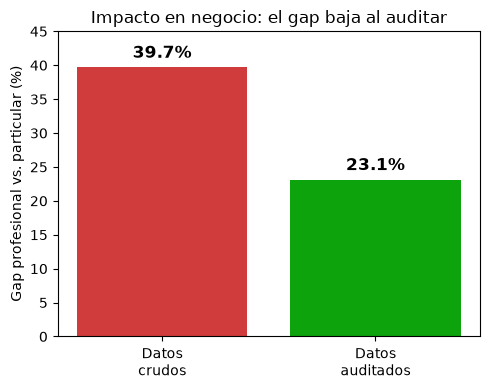

In [9]:
media_naive = listings[tiene_revenue].groupby("profesional")["estimated_revenue_l365d"].mean()
media_corr = listings[tiene_revenue & ~no_estimable].groupby("profesional")["estimated_revenue_l365d"].mean()

gap_naive = media_naive[False] - media_naive[True]
gap_corr = media_corr[False] - media_corr[True]
pct_naive = gap_naive / media_naive[False] * 100
pct_corr = gap_corr / media_corr[False] * 100

fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(["Datos\ncrudos", "Datos\nauditados"], [pct_naive, pct_corr], color=["#d03b3b", "#0ca30c"])
ax.bar_label(barras, fmt="%.1f%%", padding=4, fontsize=12, fontweight="bold")
ax.set_ylabel("Gap profesional vs. particular (%)")
ax.set_title("Impacto en negocio: el gap baja al auditar")
ax.set_ylim(0, 45)
plt.tight_layout()
plt.show()


**Resultado**: el gap pasa de 39,7% (datos crudos) a 23,1% (datos
auditados) -- se reduce en mas de un tercio. No desaparece del todo: sigue
habiendo una diferencia real entre profesionales y particulares, pero una
parte importante de lo que parecia esa diferencia era, en realidad, el error
de medicion del 0 € explicado arriba.

**Esto quiere decir que** cualquiera que use los datos sin auditar para
comparar el rendimiento de profesionales y particulares -- un inversor, un
analista, un estudio de mercado -- llegaria a una conclusion equivocada por
16,6 puntos porcentuales (39,7% en vez de 23,1%). No es un matiz pequeño: es
la diferencia entre pensar que los profesionales rinden casi el doble de mal
que los particulares, y la realidad, donde rinden peor pero de forma mucho
mas moderada. Si esa cifra se usa para decidir algo (invertir, comparar
operadores, justificar una politica), la decision parte de un numero mal
calculado.

La traduccion de este gap a una cifra en euros (149.958 €/año) se ve en el
notebook `06_modelo_ml.ipynb` y en `check_impacto_negocio_profesional.py`.


## El modelo predictivo — por qué este, y qué resultado da

**Qué intenta hacer el modelo**: adivinar, de forma automática, cuánto va a
ganar un alojamiento al año, mirando solo sus características (tipo de
propiedad, habitaciones, capacidad, barrio, si el anfitrión gestiona muchos
alojamientos, etc.) — sin que nadie le diga el resultado de antemano. Para
esto entreno un algoritmo llamado **Random Forest**, uno de los más usados
para este tipo de predicción: combina muchos "árboles de decisión" pequeños
y promedia sus resultados.

**Por qué justo este modelo, y no otro**: predice exactamente el mismo dato
que tiene el problema del 0 €: `estimated_revenue_l365d`. Si lo entreno con
datos sin tratar, le estoy enseñando con miles de ejemplos equivocados —
alojamientos ocupados y rentables etiquetados como "ganan 0 €" solo por el
error ya explicado. El modelo podría aprender un patrón falso a partir de
esos ejemplos. Por eso se usa la misma corrección (`revenue_no_estimable`)
también aquí: para no entrenarlo con ejemplos falsos. No son dos análisis
sueltos que casualmente comparten tema — es el mismo error de datos,
aplicado a dos formas distintas de usar esa información: una comparación
simple hecha por una persona, y un sistema que aprende de miles de ejemplos.

**Por qué se entrena tres veces**: una con datos crudos, y dos con datos
tratados (usando dos criterios distintos para rellenar datos faltantes —
criterio A por capacidad del alojamiento, criterio B por barrio). Si las dos
versiones tratadas dan un resultado parecido entre sí, la conclusión es
sólida, no depende de cómo decidí limpiar los datos.

**Cómo se mide si el modelo es bueno**: con el **error promedio en euros**
(cuánto se equivoca el modelo al calcular el ingreso de un alojamiento, más
bajo es mejor) y un **puntaje R² de 0 a 1** (qué % de las diferencias entre
alojamientos logra explicar el modelo, más alto es mejor, en teoría).

Resultados ya verificados y ejecutados en `notebooks/06_modelo_ml.ipynb`
(no se reentrena aquí para que este notebook corra rápido):

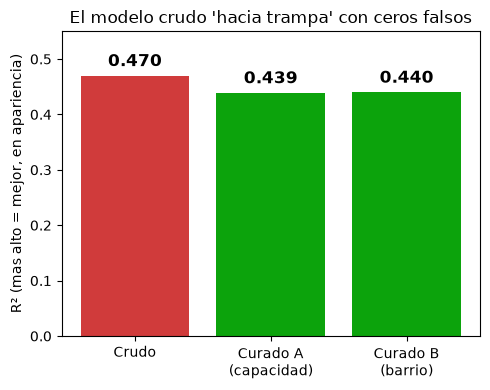

R² mas bajo con datos tratados: no es un modelo peor, es una prueba mas honesta.
Diferencia entre criterios A y B: menor al 0.1% -> la conclusion no depende
de una eleccion arbitraria de como se limpiaron los datos.


In [10]:
versiones = ["Crudo", "Curado A\n(capacidad)", "Curado B\n(barrio)"]
r2 = [0.470, 0.439, 0.440]
colores = ["#d03b3b", "#0ca30c", "#0ca30c"]

fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(versiones, r2, color=colores)
ax.bar_label(barras, fmt="%.3f", padding=4, fontsize=12, fontweight="bold")
ax.set_ylabel("R² (mas alto = mejor, en apariencia)")
ax.set_title("El modelo crudo 'hacia trampa' con ceros falsos")
ax.set_ylim(0, 0.55)
plt.tight_layout()
plt.show()

print("R² mas bajo con datos tratados: no es un modelo peor, es una prueba mas honesta.")
print("Diferencia entre criterios A y B: menor al 0.1% -> la conclusion no depende")
print("de una eleccion arbitraria de como se limpiaron los datos.")


**Si te dijera que limpiar los datos empeoro la precision del modelo,
¿pensarias que hice algo mal?** No lo hice: el modelo con datos crudos no
era mejor, estaba haciendo trampa. El 20,1% de los casos que excluimos (los
ceros artificiales) son casi gratis de adivinar: si `number_of_reviews_ltm
= 0`, basta con predecir "0 €" y aciertas casi siempre. Eso infla el
puntaje R² sin que el modelo haya aprendido nada real sobre que hace que un
alojamiento gane mas o menos. Al quitar esos casos, el modelo se enfrenta a
una prueba mas dificil y honesta -- por eso el numero baja, no porque este
peor entrenado.

**Esto quiere decir que** si alguien confiara en el modelo crudo porque su
R² es mas alto, estaria confiando en un modelo bueno para detectar un
patron artificial (reseñas = 0 -> ingreso = 0), no en uno que de verdad
prediga ingresos. Usarlo para una decision real seria arriesgado
precisamente porque PARECE mas confiable de lo que es.


## El cierre

La calidad de los datos no es un paso opcional antes del análisis, es parte
del análisis — y cambia lo que terminas creyendo que es verdad.
